In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import json
import torch.nn.functional as F

In [2]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [3]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [4]:
work_folder = 'edge_spen'
saving_folder = 'l9'
os.chdir(work_folder)

In [5]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [6]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

In [7]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))
from ppo_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ppo_ants = PPO_ants( env,
                 gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                 clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                 state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)
        

In [8]:
load_from_run = True
ppo_ants.setup_networks()
best_weigths = False

if load_from_run and best_weigths:
    ppo_ants.load_weights(saving_folder + '/weights/best_weights')
else:
    if load_from_run:
        ppo_ants.load_weights(saving_folder + '/weights')
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/critic_weights.pth", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/actor_weights.pth", weights_only=True))

In [9]:
seed = int(saving_folder[-1])

In [10]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
#beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
beta_list = [1.5, 2.5]
n_special_list = [30]
policies = [0,1,2,3,4,5,6,7,8,9]

In [11]:
import csv
import os
import numpy as np
import torch
import random
import json

for n_special in n_special_list:

    for seed in policies:
        
        saving_folder = 'l' + str(seed)

        env = Ants(n, Lx, Ly, delta_list, beta_list, decay_rate, eta, eta_special,
                    tmax, n_special, t_transient, vision=state_dim[-1])
                
        ppo_ants = PPO_ants( env,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad, use_gae=True, lam=0.95)

        ppo_ants.setup_networks()
        ppo_ants.load_weights(saving_folder + '/weights')

        filename = "component_reward_rand.csv"

        # Intestazioni delle colonne
        header = [
            "seed", "sim_seed", "n_special", "beta", "delta",
            "n_edges_list", "n_nodes_list", "reward_list", "pop_list", "pod_list"
        ]

        # Se il file non esiste, scrivi l'header
        if not os.path.exists(filename):
            with open(filename, "w", newline="") as f:
                writer = csv.writer(f)
                writer.writerow(header)
        
        for i,beta in enumerate(beta_list):
            for j,delta in enumerate(delta_list):
                sim_seed = i*len(delta_list) + j + seed*len(beta_list)*len(delta_list)
                np.random.seed(sim_seed)
                torch.manual_seed(sim_seed)
                random.seed(sim_seed)

                ppo_ants.env.reset_objects()
                ppo_ants.env.delta[:] = delta
                ppo_ants.env.beta[:] = beta
                
                ppo_ants.env.transient()
                state = ppo_ants.get_state()

                n_edges_list = []
                n_nodes_list = []
                rew_list = []
                pop_list = []
                pod_list = []

                while ppo_ants.env.t < ppo_ants.env.tmax:
                    actions = ppo_ants.policy(state)
                    next_state, reward, done = ppo_ants.execute_action(actions)
                    state = next_state.copy()
                    metrics_for_components = ppo_ants.global_reward()
                    n_edges_list.append(metrics_for_components[:,0])
                    n_nodes_list.append(metrics_for_components[:,1])
                    rew_list.append(metrics_for_components[:,2])
                    pop_list.append(ppo_ants.env.order_parameter_s())
                    pod_list.append(ppo_ants.env.order_parameter_p())

                '''rewards = rewards_for_components[:,0]
                rew = np.mean(rewards)
                len_rew = np.mean(rewards_for_components[:,1])
                edge_pen = np.mean(rewards_for_components[:,2])'''

                print(ppo_ants.env.delta[-1], ppo_ants.env.beta[-1])


                # Scriviamo direttamente nel CSV
                row_data = [
                    seed, sim_seed, n_special, ppo_ants.env.beta[-1], ppo_ants.env.delta[-1],
                    json.dumps([np.asarray(x).tolist() for x in n_edges_list]),
                    json.dumps([np.asarray(x).tolist() for x in n_nodes_list]),
                    json.dumps([np.asarray(x).tolist() for x in rew_list]),
                    json.dumps(pop_list),
                    json.dumps(pod_list)
                ]

                with open(filename, "a", newline="") as f:
                    writer = csv.writer(f)
                    writer.writerow(row_data)

        print(f"Risultati salvati per seed {seed}")

0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 0
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 1
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 2
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 3
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 4
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 5
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 6
0.3 1.5
0.4 1.5
0.5 1.5
0.6 1.5
0.7 1.5
0.8 1.5
0.3 2.5
0.4 2.5
0.5 2.5
0.6 2.5
0.7 2.5
0.8 2.5
Risultati salvati per seed 7


In [12]:
# load the dataset
import pandas as pd
import json
load = True
if load:
    dfbm = pd.read_csv("component_reward_rand.csv")
    dfbm['n_edges_list'] = dfbm['n_edges_list'].apply(json.loads)
    dfbm['n_nodes_list'] = dfbm['n_nodes_list'].apply(json.loads)
    dfbm['pop_list'] = dfbm['pop_list'].apply(json.loads)
    dfbm['pod_list'] = dfbm['pod_list'].apply(json.loads)
    dfbm['reward_list'] = dfbm['reward_list'].apply(json.loads)

In [13]:
'''for metric in ['pop', 'pod']:
    pivot = (
        dfbm.groupby(["beta", "delta"])[metric]
        .mean()
        .round(2)
        .unstack("delta")
        .sort_index(ascending=False)  # beta descending
    )
    
    # Format index and column labels to 1 decimal
    pivot.index = [f"{v:.1f}" for v in pivot.index]
    pivot.columns = [f"{v:.1f}" for v in pivot.columns]
    
    latex = pivot.to_latex(
        float_format="%.2f",
        caption=r"Average $m(T)$ smart-agents",
        label=f"tab:{metric}",
        position="ht"
    )
    print(latex)
    print()'''

'for metric in [\'pop\', \'pod\']:\n    pivot = (\n        dfbm.groupby(["beta", "delta"])[metric]\n        .mean()\n        .round(2)\n        .unstack("delta")\n        .sort_index(ascending=False)  # beta descending\n    )\n\n    # Format index and column labels to 1 decimal\n    pivot.index = [f"{v:.1f}" for v in pivot.index]\n    pivot.columns = [f"{v:.1f}" for v in pivot.columns]\n\n    latex = pivot.to_latex(\n        float_format="%.2f",\n        caption=r"Average $m(T)$ smart-agents",\n        label=f"tab:{metric}",\n        position="ht"\n    )\n    print(latex)\n    print()'

In [14]:
dfbm['how_many_components'] = dfbm['n_edges_list'].apply(lambda x: [len(edges) for edges in x])

In [15]:
dfbm['len_rew'] = dfbm.apply(lambda row: [[min(row['n_nodes_list'][k][i],env.Lx)/env.Lx for i in range(len(row['n_nodes_list'][k]))] for k in range(len(row['n_nodes_list']))], axis=1)

In [16]:
dfbm['edge_pen'] = dfbm.apply(lambda row: [-np.array(row['n_edges_list'][k]) / (np.array(row['n_nodes_list'][k]) - 1) for k in range(len(row['n_nodes_list']))], axis=1)

In [17]:
r1_results = np.zeros((len(dfbm), len(dfbm['n_edges_list'][0])))
for c in range(len(dfbm)):
    for i in range(len(dfbm['n_edges_list'][c])):
        pop = dfbm['pop_list'][c][i]
        pod = dfbm['pod_list'][c][i]
        sum_r1 = 0
        for k in range(len(dfbm['n_nodes_list'][c][i])):
            edge_pen = -dfbm['n_edges_list'][c][i][k] / (dfbm['n_nodes_list'][c][i][k] - 1)
            len_rew = min(dfbm['n_nodes_list'][c][i][k], env.Lx) / env.Lx
            reward1 = edge_pen + (len_rew*pop + pod)/2
            sum_r1 += reward1
        r1_results[c][i] = sum_r1

In [18]:
r1_results[:,-50:].reshape(10, len(beta_list), len(delta_list), 50).mean(axis=(0,3))

ValueError: cannot reshape array of size 27000 into shape (10,2,6,50)

In [19]:
dfbm['reward1'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5*row['pop_list'][i]*np.sum(row['len_rew'][i]) + \
                  0.5*row['pod_list'][i]*row['how_many_components'][i] for i in range(len(row['edge_pen']))], axis=1)

dfbm['reward2'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5*(row['pop_list'][i] + row['pod_list'][i]) for i in range(len(row['edge_pen']))], axis=1)

dfbm['reward3'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5 * row['how_many_components'][i] * (row['pop_list'][i]*min(env.Lx,
                                                                           min(row['n_nodes_list'][i]))/env.Lx + \
                  row['pod_list'][i]) for i in range(len(row['edge_pen']))], axis=1)

dfbm['reward4'] = dfbm.apply(lambda row: [np.sum(row['edge_pen'][i]) + \
                  0.5 * row['how_many_components'][i] * (row['pop_list'][i]*min(env.Lx,
                                                            np.array(row['n_nodes_list'][i]).mean())/env.Lx + \
                  row['pod_list'][i]) for i in range(len(row['edge_pen']))], axis=1)

In [20]:
dfbm['reward'] = dfbm.apply(lambda row: [np.sum(row['reward_list'][i]) for i in range(len(row['reward_list']))], axis=1)

In [21]:
dfbm['r2_mean'] = dfbm['reward2'].apply(lambda x: np.mean(x))
dfbm['r2_mean_50'] = dfbm['reward2'].apply(lambda x: np.mean(x[-50:]))
dfbm['pop_last'] = dfbm['pop_list'].apply(lambda x: x[-1])
dfbm['pod_last'] = dfbm['pod_list'].apply(lambda x: x[-1])
dfbm['r1_mean'] = dfbm['reward1'].apply(lambda x: np.mean(x))
dfbm['r1_mean_50'] = dfbm['reward1'].apply(lambda x: np.mean(x[-50:]))
dfbm['r3_mean'] = dfbm['reward3'].apply(lambda x: np.mean(x))
dfbm['r3_mean_50'] = dfbm['reward3'].apply(lambda x: np.mean(x[-50:]))
dfbm['r4_mean'] = dfbm['reward4'].apply(lambda x: np.mean(x))
dfbm['r4_mean_50'] = dfbm['reward4'].apply(lambda x: np.mean(x[-50:]))

In [22]:
"""print('avg r1', dfbm['r1_mean'].mean())
print('avg r2', dfbm['r2_mean'].mean())
print('avg r3', dfbm['r3_mean'].mean())
print('avg r4', dfbm['r4_mean'].mean())"""
"""print('avg r1 last 50', dfbm['r1_mean_50'].mean())
print('avg r2 last 50', dfbm['r2_mean_50'].mean())
print('avg r3 last 50', dfbm['r3_mean_50'].mean())"""
print('avg r4 last 50', dfbm['r4_mean_50'].mean()) 
print("stdev r1 last 50", dfbm['r4_mean_50'].std())


avg r4 last 50 -1.7826802545792373
stdev r1 last 50 1.755429585948269


In [23]:
# save dfbm['r4_mean_50']
dfbm[['seed', 'beta', 'delta', 'r4_mean_50']].to_csv("r4_mean_50_rand.csv", index=False)

# save pop and pod
dfbm[['seed', 'beta', 'delta', 'pop_last', 'pod_last']].to_csv("pop_pod_last_rand.csv", index=False)

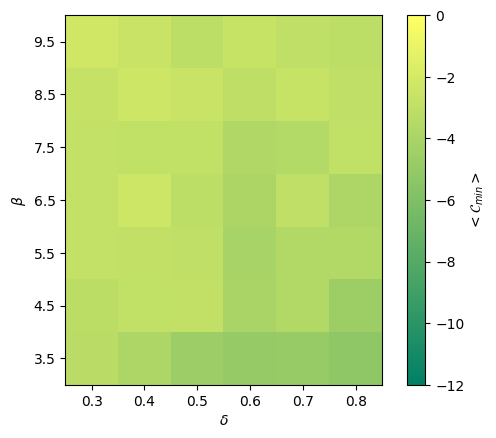

In [ ]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r3_mean'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{C}_{min}>$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

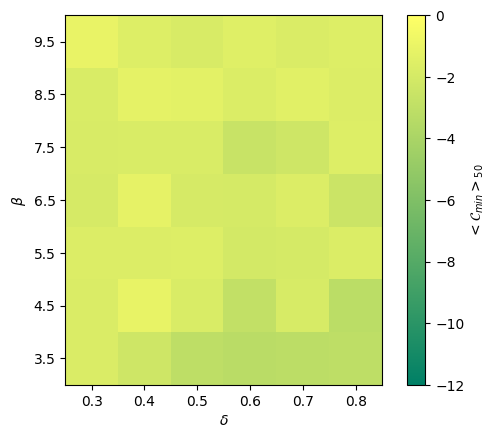

In [ ]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r3_mean_50'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{C}_{min}>_{50}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

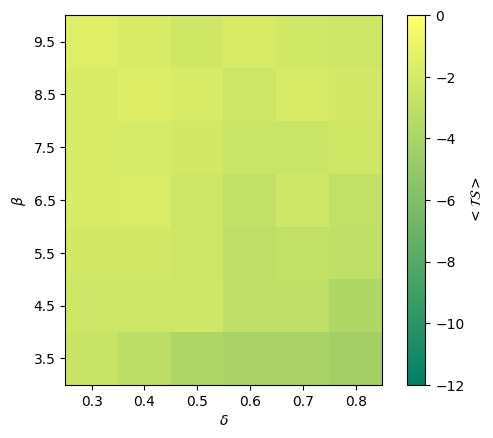

In [ ]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r4_mean'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$<\mathcal{TS}>$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

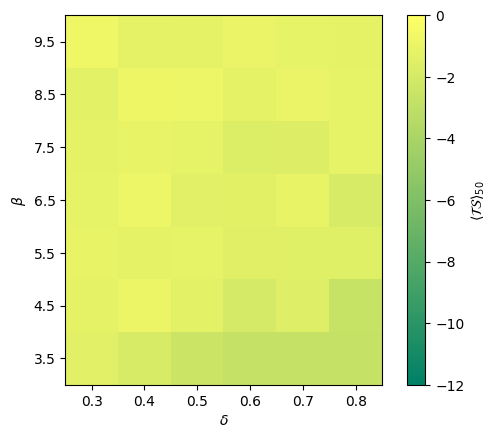

In [ ]:
import matplotlib.pyplot as plt
min_val = -12
max_val = 0
rew0 = dfbm['r4_mean_50'].to_numpy().reshape(10,len(beta_list), len(delta_list)).mean(axis=0)
plt.imshow(rew0, cmap='summer', origin='lower', vmin=min_val, vmax=max_val)
plt.colorbar(label=r'$\langle \mathcal{TS} \rangle_{50}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
# plt.title(r' $<r>_{50}$ for 30 enchanced abm ants')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

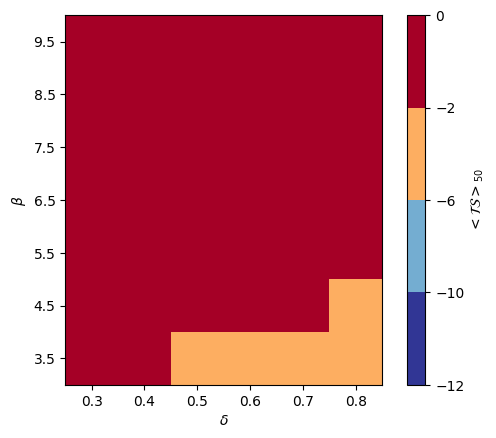

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Same heatmap data (r4_mean_50), but with threshold-based color clusters
rew0 = dfbm['r4_mean_50'].to_numpy().reshape(10, len(beta_list), len(delta_list)).mean(axis=0)

# Thresholds / bins: [-12,-10), [-10,-6), [-6,-2), [-2,0]
bounds = [-12, -10, -6, -2, 0]
cmap = mcolors.ListedColormap(['#313695', '#74add1', '#fdae61', '#a50026'])
norm = mcolors.BoundaryNorm(bounds, cmap.N)

plt.figure()
img = plt.imshow(rew0, cmap=cmap, norm=norm, origin='lower')
cbar = plt.colorbar(img, ticks=bounds)
cbar.set_label(r'$<\mathcal{TS}>_{50}$')

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.xticks(ticks=np.arange(len(delta_list)), labels=delta_list)
plt.yticks(ticks=np.arange(len(beta_list)), labels=beta_list)
plt.show()

In [ ]:
import numpy as np
import pandas as pd

beta_desc = sorted(beta_list, reverse=True)
pivot_r4_50 = (
    dfbm.groupby(['beta', 'delta'])['r4_mean']
        .mean()
        .unstack('delta')
        .reindex(index=beta_desc, columns=delta_list)
)

latex_lines = []
latex_lines.append(r"\begin{table}[h]")
latex_lines.append(r"\centering")
latex_lines.append(r"\resizebox{0.95\textwidth}{!}{%")
latex_lines.append(r"\begin{tabular}{c" + "r" * len(delta_list) + r"}")  # no pipes
latex_lines.append(r"\toprule")
latex_lines.append(
    r"\diagbox[innerwidth=1.6cm]{$\beta$}{$\delta$} & "
    + " & ".join([f"${d}$" for d in delta_list])
    + r" \\"
)
latex_lines.append(r"\midrule")
for beta in beta_desc:
    row_vals = [f"{pivot_r4_50.loc[beta, delta]:.2f}" for delta in delta_list]
    latex_lines.append(f"${beta}$ & " + " & ".join(row_vals) + r" \\")  # row ending
latex_lines.append(r"\bottomrule")
latex_lines.append(r"\end{tabular}%")
latex_lines.append(r"}")
latex_lines.append(r"\caption{Average $\langle\mathcal{TS}\rangle_{50}$ for each $(\beta, \delta)$ configuration.}")
latex_lines.append(r"\label{tab:r4_mean}")
latex_lines.append(r"\end{table}")

latex_table_r4_50 = "\n".join(latex_lines)
print(latex_table_r4_50)

\begin{table}[h]
\centering
\resizebox{0.95\textwidth}{!}{%
\begin{tabular}{crrrrrr}
\toprule
\diagbox[innerwidth=1.6cm]{$\beta$}{$\delta$} & $0.3$ & $0.4$ & $0.5$ & $0.6$ & $0.7$ & $0.8$ \\
\midrule
$9.5$ & -1.56 & -1.92 & -2.23 & -1.85 & -2.16 & -2.38 \\
$8.5$ & -1.90 & -1.61 & -1.90 & -2.32 & -1.89 & -2.15 \\
$7.5$ & -1.89 & -2.01 & -2.02 & -2.53 & -2.50 & -2.21 \\
$6.5$ & -1.90 & -1.74 & -2.34 & -2.86 & -2.27 & -2.89 \\
$5.5$ & -2.06 & -2.14 & -2.31 & -3.09 & -2.90 & -2.99 \\
$4.5$ & -2.34 & -2.34 & -2.26 & -2.96 & -2.99 & -3.78 \\
$3.5$ & -2.60 & -3.14 & -3.82 & -4.07 & -4.07 & -4.40 \\
\bottomrule
\end{tabular}%
}
\caption{Average $\langle\mathcal{TS}\rangle_{50}$ for each $(\beta, \delta)$ configuration.}
\label{tab:r4_mean}
\end{table}
